# 06 · Reinforcement learning: PPO from the imitation policies; choose and freeze the final controller

`results/FINAL_SPEC.md` §5, steps 4–6. Each network (MLP, GRU) × seed (0–4) starts from its frozen imitation policy (notebook 05) and is
trained with PPO for 1M steps (learning rate 1e-4, shield on). The checkpoint with the best validation reward (step 0 and every 100k)
is kept. The **final controller** is the network with the better mean validation reward over the 5 seeds. Everything used by the test
is frozen (hashes) at the end of this notebook.

In [1]:
import sys, os, json, hashlib, time, datetime, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from joblib import Parallel, delayed
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); os.environ["PYTHONPATH"] = str(ROOT / "src")
PROC, RES, MOD = ROOT / "data" / "processed", ROOT / "results", ROOT / "models"
assert hashlib.sha256((RES / "FINAL_SPEC.md").read_bytes()).hexdigest() == json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"], "plan changed"
imf = json.loads((RES / "imitation_freeze.json").read_text())
for k, v in imf.items():
    assert hashlib.sha256((MOD / "imitation" / k / "chosen.zip").read_bytes()).hexdigest() == v["sha256"], f"{k} changed after its freeze"
from learn import NETS, train_ppo
def run(net, seed):
    import sys, os; sys.path.insert(0, os.environ["PYTHONPATH"])
    from learn import train_ppo
    return train_ppo(os.environ["NIRANTAR_ROOT"], net, seed)
os.environ["NIRANTAR_ROOT"] = str(ROOT)
JOBS = [(n, s) for n in NETS for s in range(5)]
todo = [(n, s) for n, s in JOBS if not (MOD / "rl" / f"{n}_s{s}" / "done.json").exists()]
free = psutil.virtual_memory().available / 2**30; NJ = int(max(2, min(8, (free - 1.0) // 0.8)))
print(f"{len(todo)} PPO runs to do | free memory {free:.1f} GB -> {NJ} in parallel")
t0 = time.time()
Parallel(n_jobs=NJ)(delayed(run)(n, s) for n, s in todo)
print(f"PPO done in {(time.time() - t0) / 60:.0f} min")

10 PPO runs to do | free memory 5.7 GB -> 5 in parallel


PPO done in 83 min


## Validation results per run, learning curves for every seed, choice of the final network

,net,seed,best_step,imitation_round,imitation_val_reward,reward_per_week,LOLH_ess_h_per_home_month,cut_demand_served_pct,evening_import_kwh_per_day,battery_cycles_per_day,shield_rate_pct
0,MLP,0,1000000,0,-13.960,-11.891,3.911,90.294,9.889,1.049,1.657
1,MLP,1,500000,1,-13.936,-11.696,1.792,91.543,9.860,1.049,3.041
2,MLP,2,200000,1,-13.964,-11.969,1.764,89.729,9.970,1.057,2.550
3,MLP,3,800000,0,-13.967,-11.904,3.210,90.438,9.712,1.073,3.592
4,MLP,4,200000,1,-13.901,-11.752,1.971,89.949,9.913,1.025,3.086
5,GRU,0,900000,0,-13.247,-11.727,1.887,90.888,9.848,1.161,6.069
6,GRU,1,700000,0,-13.470,-11.630,2.177,91.621,10.097,1.072,5.192
7,GRU,2,300000,0,-13.431,-11.462,2.086,90.824,9.732,1.064,1.710
8,GRU,3,200000,0,-13.308,-11.553,2.062,90.936,9.732,1.068,3.714
9,GRU,4,400000,0,-12.899,-11.552,2.347,91.988,9.986,1.097,3.029


reward_per_week        LOLH_ess_h_per_home_month         \
               mean    std                      mean    std   
net                                                           
GRU         -11.585  0.099                     2.112  0.168   
MLP         -11.842  0.114                     2.530  0.976   

    cut_demand_served_pct        evening_import_kwh_per_day         \
                     mean    std                       mean    std   
net                                                                  
GRU                91.252  0.523                      9.879  0.160   
MLP                90.391  0.702                      9.869  0.096   

    battery_cycles_per_day        shield_rate_pct         
                      mean    std            mean    std  
net                                                       
GRU                  1.093  0.041           3.943  1.728  
MLP                  1.051  0.017           2.785  0.730

final controller (best mean validation reward over 5 seeds): GRU


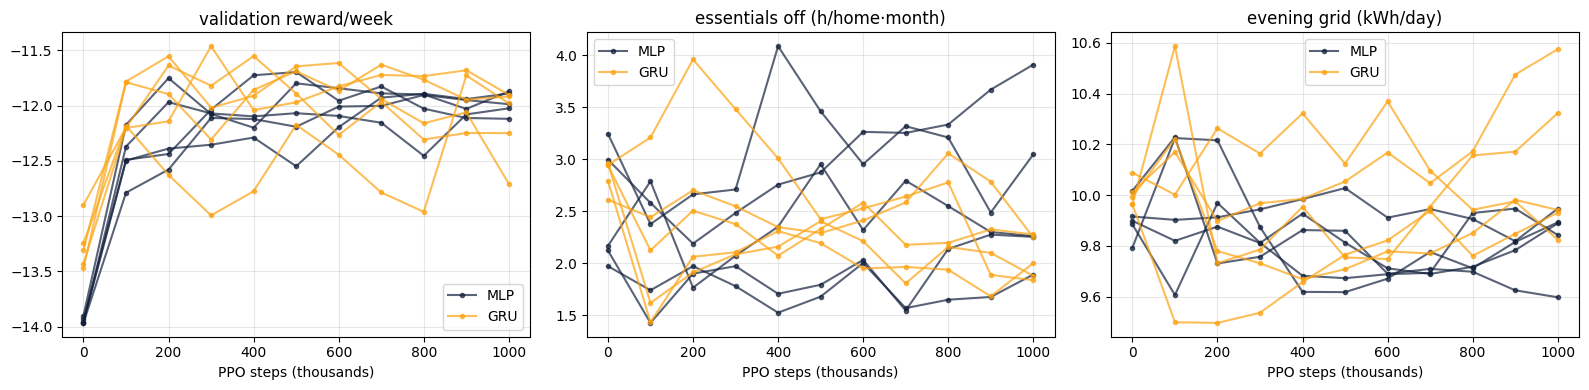

In [2]:
rows = []
for n, s in JOBS:
    d = MOD / "rl" / f"{n}_s{s}"; ep = pd.read_csv(d / "best_val_per_episode.csv"); b = json.loads((d / "best.json").read_text())
    rows.append({"net": n, "seed": s, "best_step": b["step"], "imitation_round": imf[f"{n}_s{s}"]["chosen_round"],
                 "imitation_val_reward": imf[f"{n}_s{s}"]["val_reward"], **ep.drop(columns="episode").mean().to_dict()})
PR = pd.DataFrame(rows); PR.to_csv(RES / "rl_val_per_run.csv", index=False)
cols = ["reward_per_week", "LOLH_ess_h_per_home_month", "cut_demand_served_pct", "evening_import_kwh_per_day", "battery_cycles_per_day", "shield_rate_pct"]
display(PR[["net", "seed", "best_step", "imitation_round", "imitation_val_reward"] + cols].round(3))
summ = PR.groupby("net")[cols].agg(["mean", "std"]).round(3); display(summ)
FINAL = PR.groupby("net").reward_per_week.mean().idxmax()
print("final controller (best mean validation reward over 5 seeds):", FINAL)
TR = pd.concat([pd.read_csv(MOD / "rl" / f"{n}_s{s}" / "trajectory.csv") for n, s in JOBS], ignore_index=True); TR.to_csv(RES / "rl_val_trajectories.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n, c in zip(NETS, ["#14213D", "#FCA311"]):
    for s in range(5):
        t = TR[(TR.net == n) & (TR.seed == s)]
        for a, m in zip(ax, ["reward_per_week", "LOLH_ess_h_per_home_month", "evening_import_kwh_per_day"]):
            a.plot(t.step / 1e3, t[m], color=c, alpha=.7, marker=".", label=n if s == 0 else None)
for a, t in zip(ax, ["validation reward/week", "essentials off (h/home·month)", "evening grid (kWh/day)"]):
    a.set_title(t); a.set_xlabel("PPO steps (thousands)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(RES / "figures" / "06_rl_validation_curves.png", dpi=130); plt.show()

## Freeze everything the test uses

In [3]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
freeze = {"created": datetime.datetime.now().isoformat(timespec="seconds"), "spec_sha256": json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"],
          "final_net": FINAL, "mpc_cc": json.loads((RES / "mpc_cc_choice.json").read_text()),
          "forecasters_sha256": sha(MOD / "forecasters.pkl"),
          "checkpoints": {f"{n}_s{s}": {"sha256": sha(MOD / "rl" / f"{n}_s{s}" / "best_model.zip"), **json.loads((MOD / "rl" / f"{n}_s{s}" / "best.json").read_text())} for n, s in JOBS},
          "reference_ppo_bc_v3": json.loads((RES / "reference_manifest.json").read_text())}
(RES / "freeze.json").write_text(json.dumps(freeze, indent=1))
print("frozen:", FINAL, "| MPC-CC eps*", freeze["mpc_cc"]["eps_star"], "|", len(freeze["checkpoints"]), "checkpoints")

frozen: GRU | MPC-CC eps* 0.1 | 10 checkpoints
